In [7]:
import matplotlib.pyplot as plt
import tree_sitter_python as tsp
from tree_sitter import Language, Parser, Query, QueryCursor

from data import Cst

PY = Language(tsp.language())
parser = Parser(PY)

CODE = b"""
def factorial(x: int = 50):
    if x == 1:
        return 1
    else: 
"""


In [8]:
query = Query(PY, "(function_definition _) @functions")
captures = QueryCursor(query).captures(parser.parse(CODE).root_node)
function = captures["functions"][0]

In [9]:
cst = Cst.from_parse_tree(
    "python", CODE[function.start_byte : function.end_byte], function
)

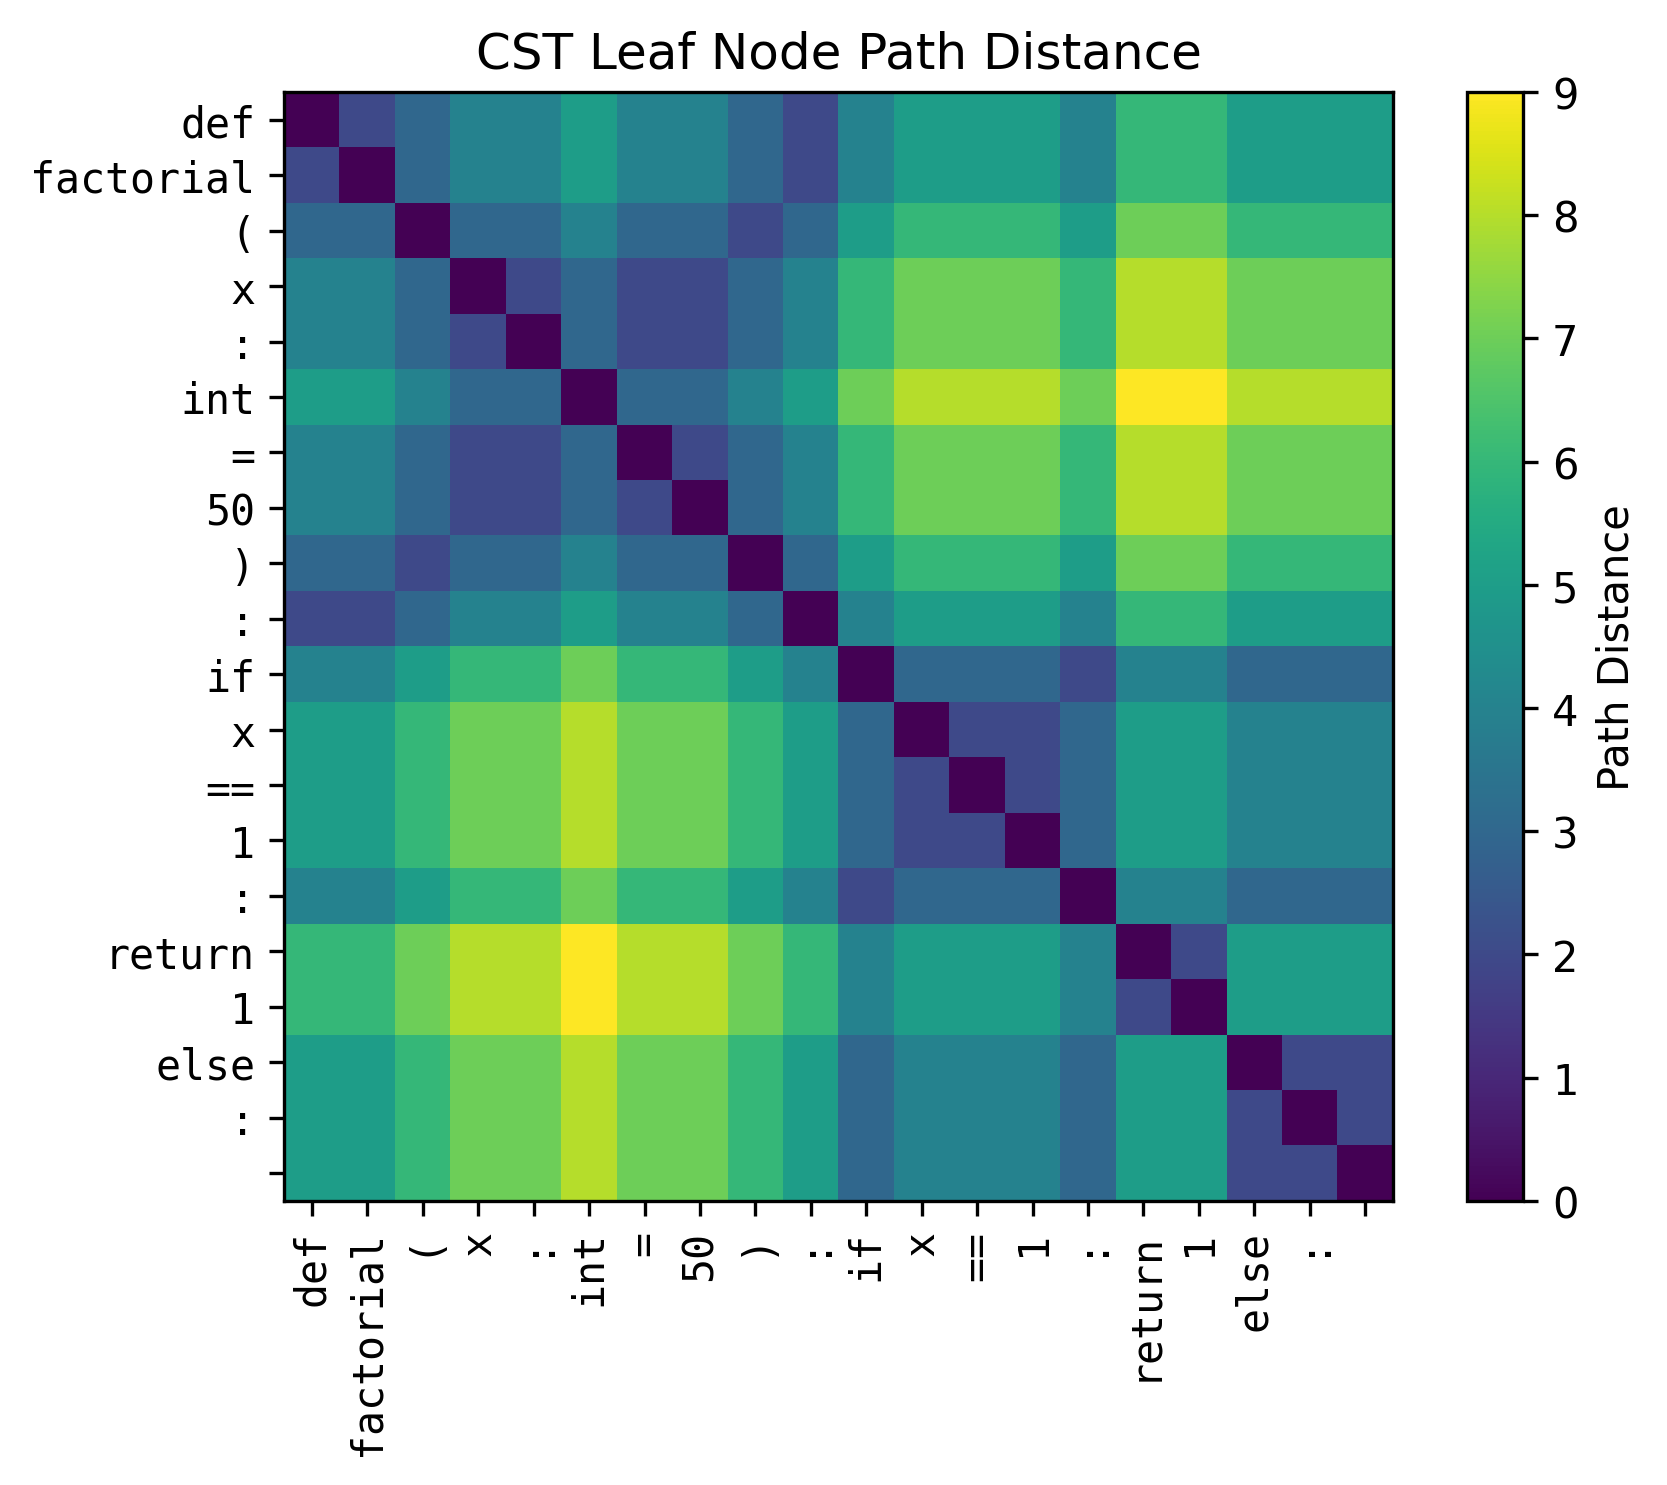

In [10]:
plt.figure(dpi=300)
plt.title("CST Leaf Node Path Distance")
plt.imshow(cst.distance)
plt.xticks(
    range(cst.num_leaves),
    [leaf.text for leaf in cst.leaves],
    rotation=90,
    font="monospace",
)
plt.yticks(range(cst.num_leaves), [leaf.text for leaf in cst.leaves], font="monospace")
plt.colorbar(label="Path Distance")
plt.show()

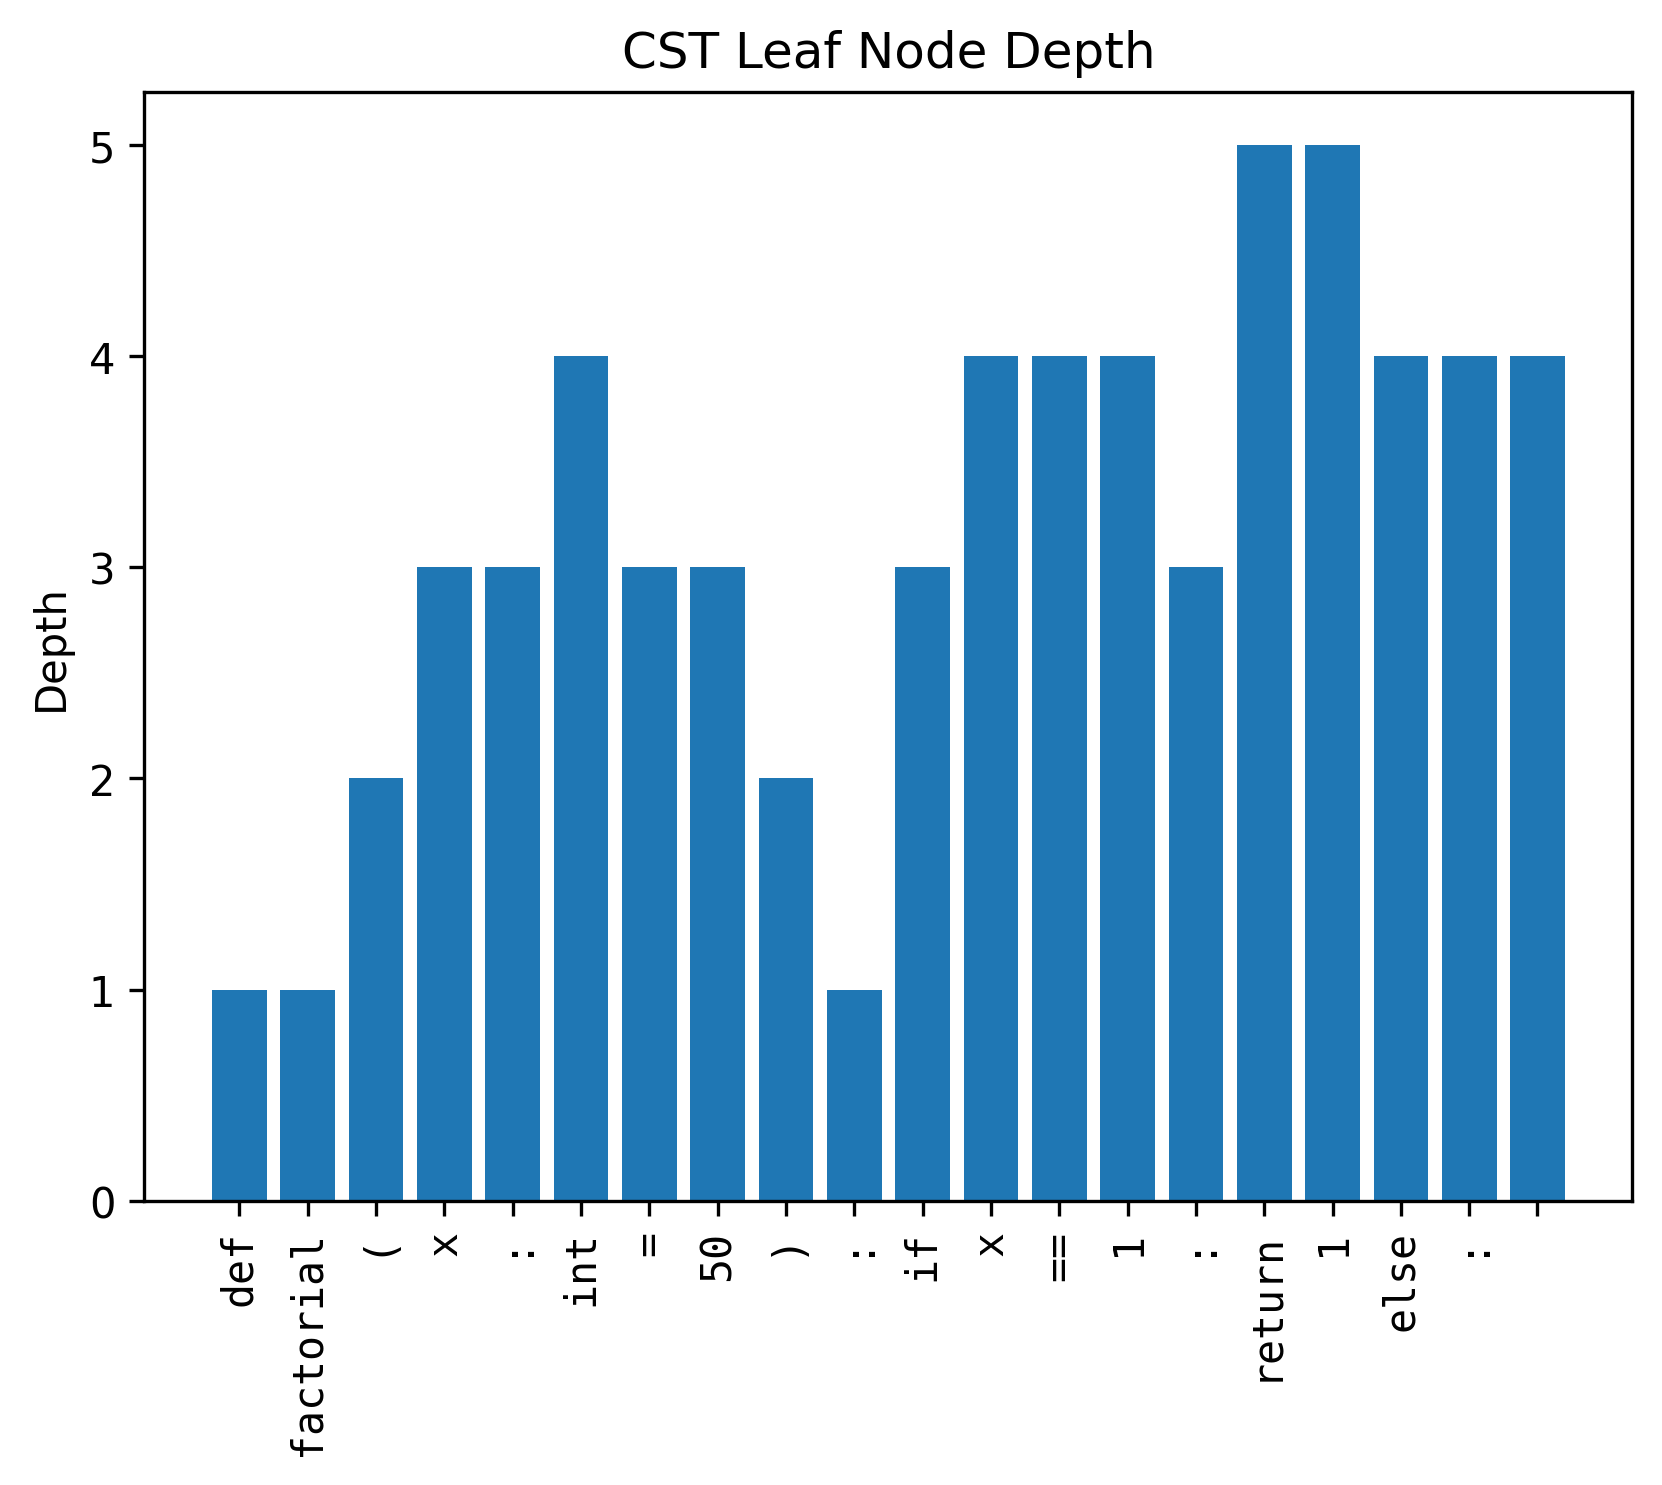

In [12]:
plt.figure(dpi=300)
plt.title("CST Leaf Node Depth")
plt.bar(range(cst.num_leaves), cst.depth[cst.leaf_indicies])
plt.xticks(
    range(cst.num_leaves),
    [leaf.text for leaf in cst.leaves],
    rotation=90,
    font="monospace",
)
plt.ylabel("Depth")
plt.show()